# Mapping arXiv papers with IMSTE and UMAP

This notebook follows the data and large-scale workflow in the [UMAP very large datasets guide](https://umap-learn.readthedocs.io/en/latest/large_datasets.html), using arXiv paper titles, abstracts, and primary categories. It creates a manageable local sample, embeds each paper's text, fits UMAP and IMSTE to the same vectors, and renders category density with Datashader.

The UMAP guide describes 3,080,258 papers embedded into 4,096 dimensions by F2LLM-v2 8B (a little over 50 GB of float32 vectors). Its code names `arxiv_jun_2026_vectors_f2llm-v2-8B.npy` and `arxiv_jun_2026_full_dataframe.parquet`, but the guide does not link a download for those precomputed artifacts. This notebook can load them if you obtain them separately. Otherwise, it downloads the public arXiv metadata mirror from Kaggle, selects a reproducible random sample, and generates smaller text embeddings locally. That fallback follows the same title-and-abstract idea, but it will not reproduce the guide's exact vectors or layout.

The default sample is 20,000 papers so both methods can run on a typical workstation. Full-corpus UMAP needs substantial RAM and compute; the full F2LLM array alone is over 50 GB. IMSTE is evaluated on the same sample and is intended here as a comparative experiment, not a claim that it matches UMAP's million-row scaling.


Run this once in the notebook environment from the repository root. It installs IMSTE with its notebook extras, plus the packages used for text embeddings, arXiv download, and large-scale rendering. Kaggle account authentication is separate; do not put an API token in this notebook.

In [ ]:
%pip install -e ".[notebook]" -U "umap-learn[rinnd]>=0.6" sentence-transformers kaggle glasbey

## 2. Get the arXiv metadata

The [Cornell University arXiv dataset on Kaggle](https://www.kaggle.com/datasets/Cornell-University/arxiv) provides the metadata snapshot with titles, abstracts, and categories. The Kaggle mirror currently describes metadata for 1.7M+ papers; its contents are updated, so the notebook reads the available file rather than assuming a fixed row count.

1. Sign in to Kaggle and authenticate the CLI. The current CLI supports `kaggle auth login`; alternatively create an API token from [Kaggle account settings](https://www.kaggle.com/settings) and configure it using Kaggle's [API instructions](https://www.kaggle.com/docs/api).
2. Inspect files with `kaggle datasets files Cornell-University/arxiv` if you want to confirm the snapshot filename.
3. The cell below downloads and unpacks the metadata when needed, validates the first and final JSONL records, and reuses a complete local copy. If it finds an interrupted or corrupt copy, it removes that partial copy and downloads a clean one.

This downloads metadata only; it does not download PDFs or the UMAP guide's precomputed vector files.


In [2]:
%load_ext autoreload
%autoreload 2

%config InlineBackend.figure_format = 'retina'

from pathlib import Path
import json
import subprocess

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "pyproject.toml").exists() and (PROJECT_ROOT.parent / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data" / "arxiv"
DATA_DIR.mkdir(parents=True, exist_ok=True)


def is_complete_jsonl(path):
    """Check the first and final records so interrupted extractions are not reused."""
    try:
        if not path.is_file() or path.stat().st_size == 0:
            return False
        with path.open("rb") as file:
            first_line = file.readline()
            file.seek(max(0, path.stat().st_size - 8 * 1024 * 1024))
            tail_lines = file.read().splitlines()
        json.loads(first_line)
        json.loads(tail_lines[-1])
        return True
    except (OSError, ValueError, json.JSONDecodeError, IndexError):
        return False


DOWNLOAD_METADATA = True  # Download automatically if the local JSONL is missing or incomplete.
FORCE_METADATA_DOWNLOAD = False  # Set True only when you intentionally want a fresh snapshot.
metadata_files = sorted(DATA_DIR.glob("*.json"))
jsonl_path = next((path for path in metadata_files if "metadata" in path.name.lower()), None)
metadata_is_valid = jsonl_path is not None and is_complete_jsonl(jsonl_path)

if DOWNLOAD_METADATA and (FORCE_METADATA_DOWNLOAD or not metadata_is_valid):
    if FORCE_METADATA_DOWNLOAD or jsonl_path is not None:
        print("Removing incomplete local download before fetching a clean copy.")
        for path in DATA_DIR.glob("*.json"):
            path.unlink(missing_ok=True)
        for path in DATA_DIR.glob("*.zip"):
            path.unlink(missing_ok=True)
        for path in DATA_DIR.glob("*.kaggle-partial"):
            path.unlink(missing_ok=True)
    subprocess.run(
        ["kaggle", "datasets", "download", "Cornell-University/arxiv",
         "-p", str(DATA_DIR), "--unzip", "--force"],
        check=True,
    )
    metadata_files = sorted(DATA_DIR.glob("*.json"))
    jsonl_path = next((path for path in metadata_files if "metadata" in path.name.lower()), None)
    metadata_is_valid = jsonl_path is not None and is_complete_jsonl(jsonl_path)

print("Data directory:", DATA_DIR)
print("JSON files:", [path.name for path in metadata_files])
if not metadata_is_valid:
    raise RuntimeError(
        "The arXiv metadata JSONL is missing or incomplete. Check Kaggle's download output, "
        "available disk space, and then rerun this cell."
    )


Data directory: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/IteratedMinimumSpanningTree/data/arxiv
JSON files: ['arxiv-metadata-oai-snapshot.json']


## 3. Choose the precomputed or local-embedding path

If you have the two artifacts named in the UMAP guide, place them in `data/arxiv/` and set `USE_GUIDE_ARTIFACTS = True`. Otherwise, the notebook samples the Kaggle JSONL metadata and creates 384-dimensional vectors with `all-MiniLM-L6-v2`.

`MAX_PAPERS` controls the sample size. On the local-embedding path, the sampled paper metadata and vectors are saved under `data/arxiv/cache/`. Rerunning with the same source snapshot, sample size, seed, and model loads that cache instead of scanning and embedding again. Changing any of those inputs creates a separate cache. The download cell also skips Kaggle when the metadata JSON is already present.


In [3]:
import hashlib
import json
import numpy as np
import pandas as pd

RANDOM_STATE = 42
MAX_PAPERS = 80_000
JSON_CHUNK_SIZE = 50_000
USE_GUIDE_ARTIFACTS = False
GUIDE_VECTORS = DATA_DIR / "arxiv_jun_2026_vectors_f2llm-v2-8B.npy"
GUIDE_METADATA = DATA_DIR / "arxiv_jun_2026_full_dataframe.parquet"

if USE_GUIDE_ARTIFACTS:
    if not (GUIDE_VECTORS.exists() and GUIDE_METADATA.exists()):
        raise FileNotFoundError("Place both UMAP guide artifacts in data/arxiv before enabling USE_GUIDE_ARTIFACTS.")
    vector_store = np.load(GUIDE_VECTORS, mmap_mode="r")
    guide_metadata = pd.read_parquet(GUIDE_METADATA, columns=["categories"])
    if vector_store.shape[0] != len(guide_metadata):
        raise ValueError("Guide vectors and metadata have different row counts; check their versions/order.")
    rng = np.random.default_rng(RANDOM_STATE)
    selected_rows = np.sort(rng.choice(len(guide_metadata), size=min(MAX_PAPERS, len(guide_metadata)), replace=False))
    X = np.asarray(vector_store[selected_rows], dtype=np.float32)
    papers = guide_metadata.iloc[selected_rows].reset_index(drop=True)
    embedding_model_name = "UMAP guide F2LLM-v2 8B vectors"
else:
    jsonl_path = next((path for path in metadata_files if "metadata" in path.name.lower()), None)
    if jsonl_path is None:
        raise FileNotFoundError("No arXiv metadata JSONL found. Set DOWNLOAD_METADATA=True or place the Kaggle snapshot in data/arxiv.")

    # Key the cache by source snapshot identity and all choices that affect sampling or vectors.
    source_stat = jsonl_path.stat()
    embedding_model_name = "sentence-transformers/all-MiniLM-L6-v2"
    cache_config = {
        "source_name": jsonl_path.name,
        "source_size": source_stat.st_size,
        "source_mtime_ns": source_stat.st_mtime_ns,
        "max_papers": MAX_PAPERS,
        "random_state": RANDOM_STATE,
        "embedding_model": embedding_model_name,
        "cache_format": 1,
    }
    cache_key = hashlib.sha256(
        json.dumps(cache_config, sort_keys=True).encode("utf-8")
    ).hexdigest()[:16]
    CACHE_DIR = DATA_DIR / "cache"
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    SAMPLE_CACHE = CACHE_DIR / f"arxiv_sample_{cache_key}.pkl"
    VECTOR_CACHE = CACHE_DIR / f"arxiv_vectors_{cache_key}.npy"

    if SAMPLE_CACHE.exists() and VECTOR_CACHE.exists():
        papers = pd.read_pickle(SAMPLE_CACHE)
        X = np.load(VECTOR_CACHE, mmap_mode="r")
        print(f"Loaded cached sample and vectors: {len(papers):,} papers, {X.shape[1]:,} features.")
    else:
        # Reservoir sampling gives a uniform sample without holding all metadata in memory.
        rng = np.random.default_rng(RANDOM_STATE)
        reservoir = pd.DataFrame({
            "title": pd.Series(dtype="object"),
            "abstract": pd.Series(dtype="object"),
            "categories": pd.Series(dtype="object"),
            "_priority": pd.Series(dtype="float64"),
        })
        rows_seen = 0
        for chunk in pd.read_json(jsonl_path, lines=True, chunksize=JSON_CHUNK_SIZE):
            chunk = chunk[["title", "abstract", "categories"]].copy()
            chunk["_priority"] = rng.random(len(chunk))
            reservoir = pd.concat([reservoir, chunk], ignore_index=True)
            if len(reservoir) > MAX_PAPERS:
                reservoir = reservoir.nsmallest(MAX_PAPERS, "_priority")
            rows_seen += len(chunk)
            print(f"Scanned {rows_seen:,} metadata rows; retained {len(reservoir):,} papers", end="\r")
        papers = reservoir.sort_values("_priority").drop(columns="_priority").reset_index(drop=True)
        texts = (papers["title"].fillna("").str.strip() + "\n\n" + papers["abstract"].fillna("").str.strip()).tolist()
        print(f"\nLoaded {len(papers):,} of {rows_seen:,} available papers from {jsonl_path.name}.")

        from sentence_transformers import SentenceTransformer
        text_model = SentenceTransformer(embedding_model_name)
        X = text_model.encode(
            texts,
            batch_size=128,
            show_progress_bar=True,
            normalize_embeddings=True,
            convert_to_numpy=True,
        ).astype(np.float32, copy=False)

        # Write temporary files first so interrupted writes do not look like valid cache entries.
        sample_tmp = SAMPLE_CACHE.with_suffix(".tmp.pkl")
        vector_tmp = VECTOR_CACHE.with_suffix(".tmp.npy")
        papers.to_pickle(sample_tmp)
        with vector_tmp.open("wb") as vector_file:
            np.save(vector_file, X)
        sample_tmp.replace(SAMPLE_CACHE)
        vector_tmp.replace(VECTOR_CACHE)
        print("Saved reusable sample and vectors to", CACHE_DIR)

print("Embedding model:", embedding_model_name)
print("Vector matrix:", X.shape, X.dtype)
print("Metadata rows:", len(papers))
assert X.shape[0] == len(papers)


Loaded cached sample and vectors: 80,000 papers, 384 features.
Embedding model: sentence-transformers/all-MiniLM-L6-v2
Vector matrix: (80000, 384) float32
Metadata rows: 80000


## 4. Prepare primary categories

Use the first whitespace-separated arXiv category as the primary category. The UMAP guide groups most legacy physics archives under physics and keeps the main non-physics archives as their own domains. This makes the large-scale density plots easier to read than coloring every subcategory separately.


In [4]:
import glasbey

primary_category = papers["categories"].fillna("unknown").str.split().str[0]
archive = primary_category.str.split(".").str[0]
domain_names = {
    "cs": "computer science",
    "math": "mathematics",
    "eess": "engineering",
    "stat": "statistics",
    "q-bio": "biology",
    "q-fin": "finance",
    "econ": "economics",
}
domain = archive.map(domain_names).fillna("physics")
domain_order = domain.value_counts().index.tolist()
labels = pd.Categorical(domain, categories=domain_order)
palette = glasbey.create_block_palette([1] * len(domain_order), optimize_palette=False)
color_key = dict(zip(domain_order, palette))
display(pd.DataFrame({"primary_category": primary_category, "domain": domain}).groupby("domain", observed=True).size().sort_values(ascending=False).rename("papers"))

domain
physics             38702
computer science    20755
mathematics         15139
engineering          2167
statistics           1624
biology               924
finance               364
economics             325
Name: papers, dtype: int64

The linked guide's large-corpus recipe uses UMAP 0.6's newer pipeline, recursive initialization, and `repulsion_strength=8`. This notebook uses those settings and the guide's default 200 epochs. The local MiniLM sample remains different from the guide's full F2LLM corpus, and datasets below 200,000 rows do not activate UMAP's large-data hard-negative sampling by default. Matching the broad map therefore requires matching the input corpus and vectors, not only tuning layout parameters.

In [ ]:
import umap
import time

N_NEIGHBORS = 15
UMAP_EPOCHS = 200
UMAP_REPULSION_STRENGTH = 8

umap_started = time.perf_counter()
umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=N_NEIGHBORS,
    min_dist=0.1,
    repulsion_strength=UMAP_REPULSION_STRENGTH,
    metric="cosine",
    compatibility_layout=False,
    nearest_neighbor_backend="rinnd",
    init="recursive",
    random_state=RANDOM_STATE,
    n_epochs=UMAP_EPOCHS,
    verbose=True,
)
Z_umap = umap_model.fit_transform(X)
umap_seconds = time.perf_counter() - umap_started
print(f"UMAP fit: {umap_seconds / 60:.1f} min")

## 6. Fit IMSTE on the same vectors, starting from UMAP coordinates

FAMST builds IMSTE's approximate spanning-tree graph from the input vectors. The optimizer then starts from the already-computed `Z_umap` coordinates, with rows in the same paper order. IMSTE still optimizes those coordinates according to its own spanning-tree objective, so the final result can move away from UMAP. `n_msts` and `n_epochs` control graph repetitions and optimization time.


In [10]:
from imste._estimator import IteratedMinimumSpanningTreeEmbedder
import time

imste_started = time.perf_counter()
imste_model = IteratedMinimumSpanningTreeEmbedder(
    n_components=2,
    n_msts=4,
    n_epochs=400,
    negative_ratio=1,
    lambda_rep=0.5,
    mst_method="famst",
    mst_neighbors=5,
    pca_init=True,
    #init_coordinates=Z_umap,
    random_state=RANDOM_STATE,
    device="auto",
)
Z_imste = imste_model.fit_transform(X)
imste_seconds = time.perf_counter() - imste_started
print(f"IMSTE fit: {imste_seconds / 60:.1f} min")

IMSTE fit: 0.8 min


## 7. Render millions of points without overplotting

Datashader aggregates points per output pixel, so the same plotting code remains useful as `MAX_PAPERS` grows. You can zoom by passing coordinate ranges to `render_embedding`; each render still aggregates the selected points at full pixel resolution.


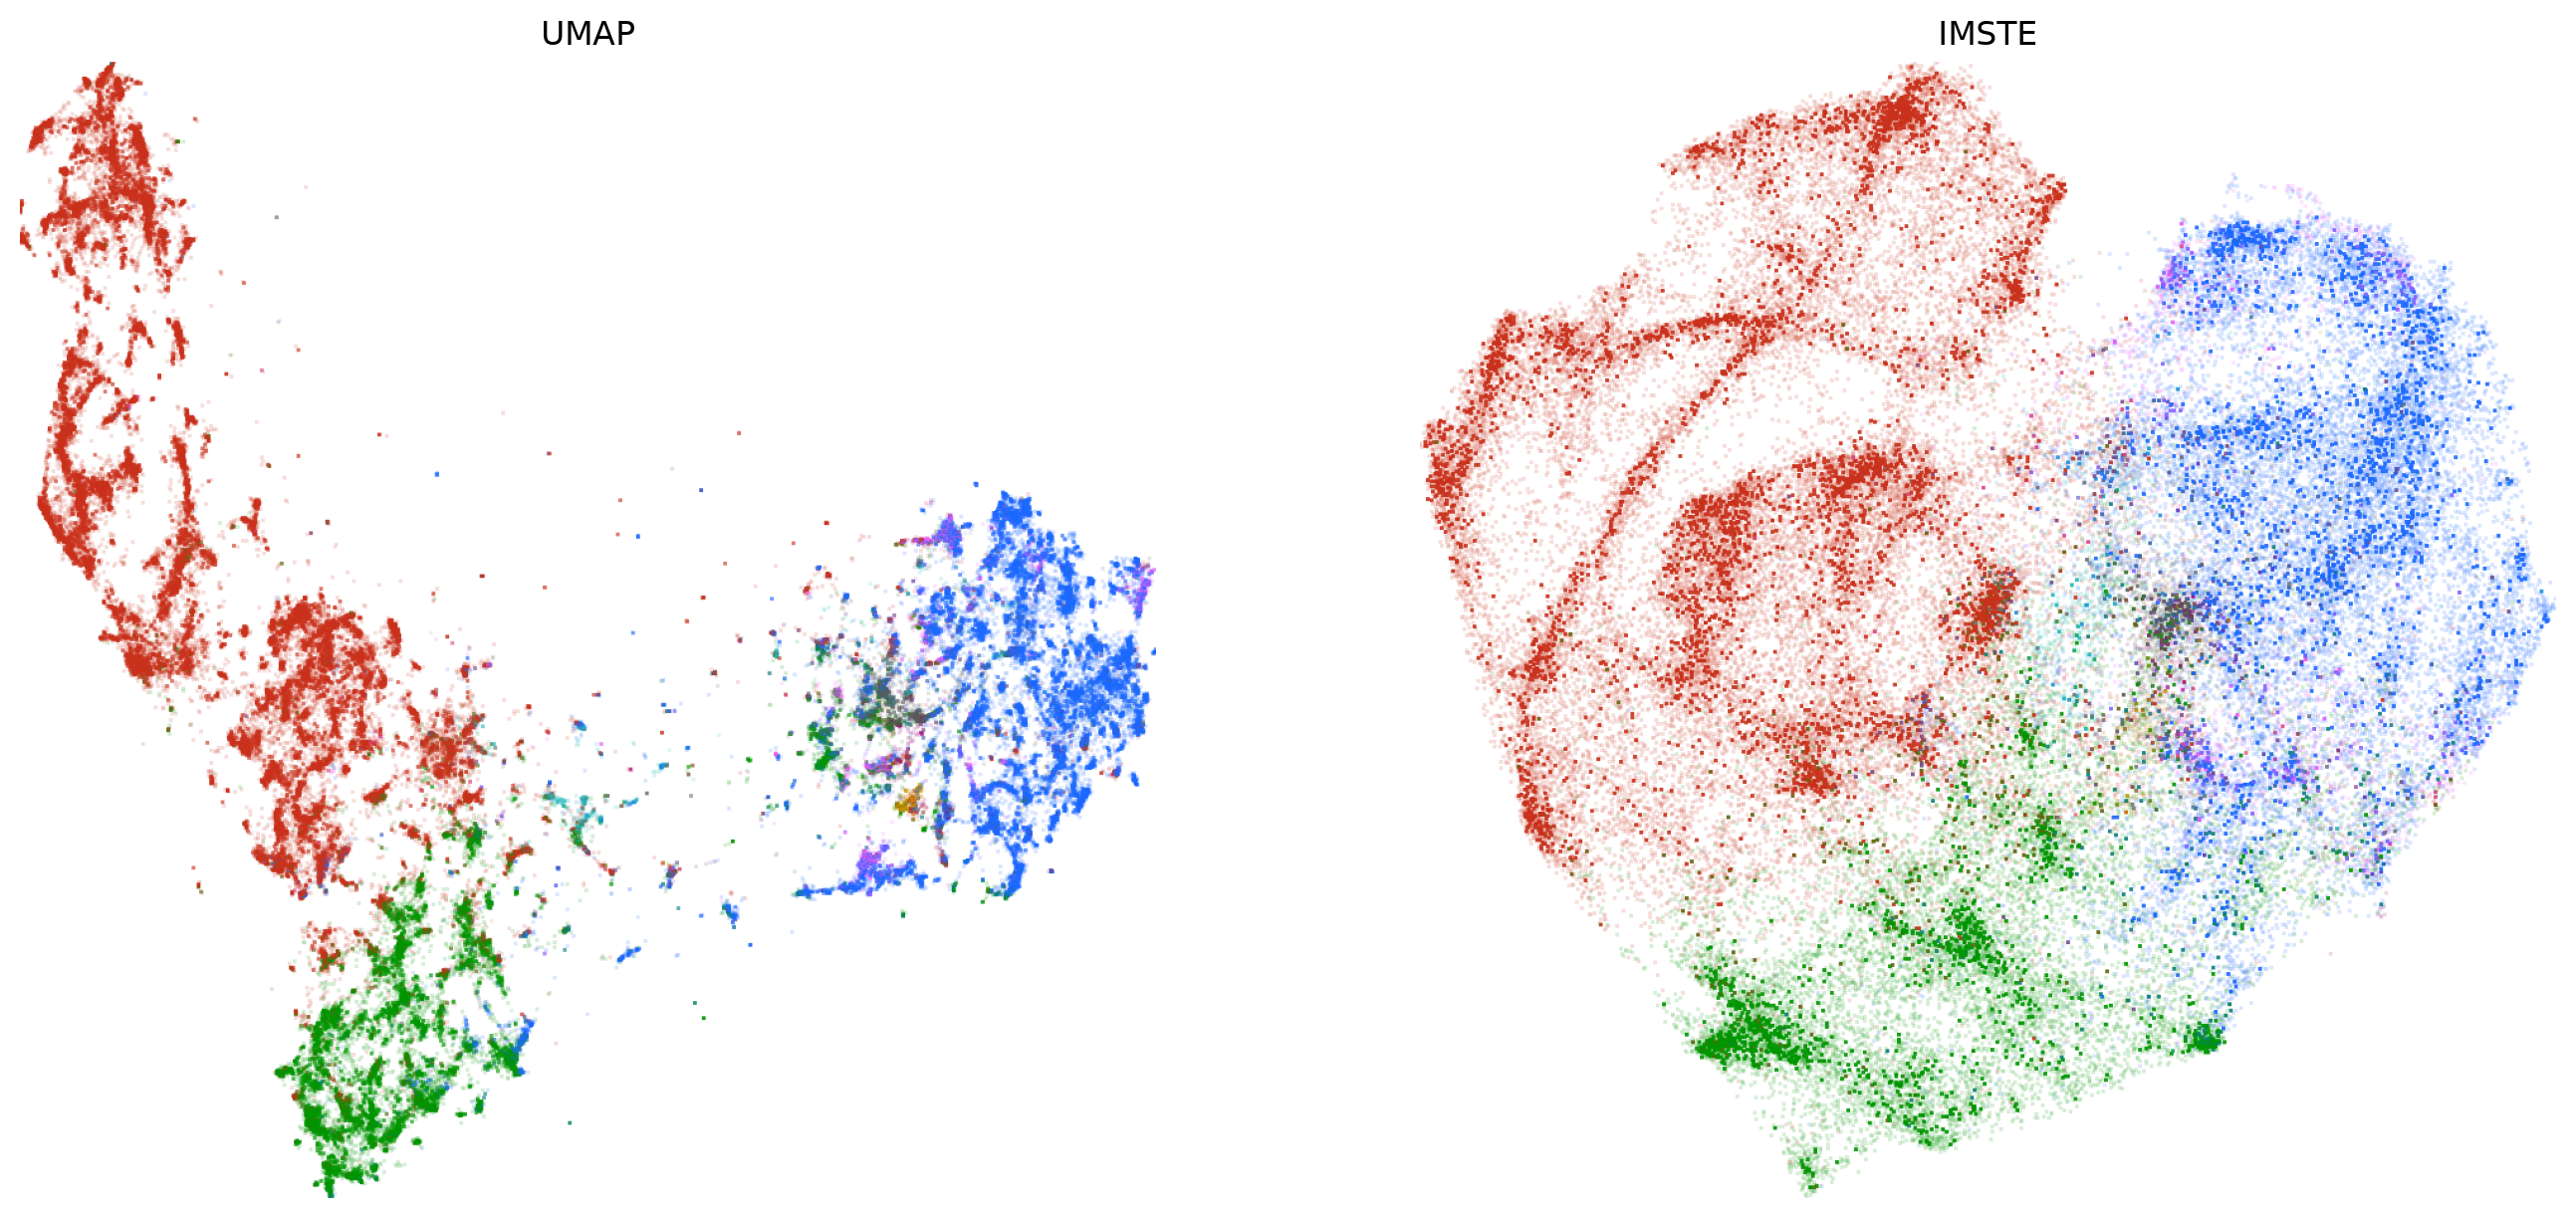

In [11]:
import matplotlib.pyplot as plt
from IPython.display import display
from imste.visualization import render_datashader_embedding

fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)
for ax, embedding, title in zip(
    axes,
    (Z_umap, Z_imste),
    ("UMAP", "IMSTE"),
):
    image = render_datashader_embedding(
        embedding,
        labels,
        label_key="label",
        color_key=color_key,
        width=900,
        height=900,
        spread_px=1,  # Fixed mark radius in pixels; try 1 or 3.
    )
    ax.imshow(image.to_pil())
    ax.set_title(title)
    ax.set_axis_off()
plt.show()

## 8. What this experiment does and does not reproduce

- The UMAP guide's data pipeline uses title-plus-abstract text, 4,096-dimensional F2LLM-v2 8B vectors, and category metadata. The guide reports 3,080,258 rows and a vector array larger than 50 GB.
- The Kaggle route here gets the arXiv metadata snapshot; this notebook computes its own vectors with `all-MiniLM-L6-v2` for a sampled set of papers. The model, sample, and resulting coordinates differ from the guide.
- To use the guide's exact vectors, obtain its `.npy` and `.parquet` artifacts separately and put them in `data/arxiv/`; then enable `USE_GUIDE_ARTIFACTS`.
- UMAP and IMSTE have different graph builders and optimizers. Compare broad category structure and local neighborhoods as exploratory evidence, not as a single quality ranking.

For more detail on nearest-neighbor search reuse, recursive initialization, repulsion strength, and hard negative sampling, see the [UMAP large-dataset guide](https://umap-learn.readthedocs.io/en/latest/large_datasets.html). The Kaggle dataset's contents and license notes are on its [dataset page](https://www.kaggle.com/datasets/Cornell-University/arxiv).
